In [1]:
import torch
import torch.nn as nn

torch.manual_seed(42)

print(torch.__version__)

2.14.1+cpu


In [2]:
import random

random.seed(42)

def make_example():

    numbers = list(range(1, 7))

    random.shuffle(numbers)

    a_index = numbers.index(1)

    b_index = numbers.index(2)

    label = int(
        a_index < b_index
    )

    return numbers, label

for _ in range(5):

    sequence, label = make_example()

    print(
        sequence,
        label
    )

[4, 2, 3, 5, 1, 6] 0
[4, 1, 3, 5, 6, 2] 1
[4, 2, 3, 1, 5, 6] 0
[2, 3, 4, 5, 6, 1] 0
[2, 4, 3, 1, 6, 5] 0


In [3]:
examples = []

labels = []

for _ in range(2000):

    sequence, label = make_example()

    examples.append(sequence)

    labels.append(label)

X = torch.tensor(
    examples,
    dtype=torch.long
)

y = torch.tensor(
    labels,
    dtype=torch.long
)

print(
    X.shape,
    y.shape
)

torch.Size([2000, 6]) torch.Size([2000])


In [4]:
train_size = 1400
val_size = 300
test_size = 300

X_train = X[:train_size]
y_train = y[:train_size]

X_val = X[
    train_size:
    train_size + val_size
]

y_val = y[
    train_size:
    train_size + val_size
]

X_test = X[-test_size:]
y_test = y[-test_size:]

print(
    X_train.shape,
    X_val.shape,
    X_test.shape
)

torch.Size([1400, 6]) torch.Size([300, 6]) torch.Size([300, 6])


In [5]:
baseline = max(
    y_train.float().mean().item(),
    1 - y_train.float().mean().item()
)

print(
    "Baseline:",
    round(
        baseline,
        3
    )
)

Baseline: 0.507


In [7]:
class TinyTransformer(nn.Module):

    def __init__(self):

        super().__init__()

        self.token_embed = nn.Embedding(7, 16)

        self.position_embed = nn.Embedding(6, 16)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=16,
            nhead=2,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=1
        )

        self.classifier = nn.Linear(
            16,
            2
        )

        self.use_positions = True

    def forward(self, x):

        tokens = self.token_embed(x)

        if self.use_positions:

            positions = torch.arange(
                x.size(1)
            ).to(x.device)

            tokens = (
                tokens +
                self.position_embed(positions)
            )

        encoded = self.encoder(tokens)

        pooled = encoded.mean(dim=1)

        return self.classifier(pooled)

model = TinyTransformer()

print(model)

TinyTransformer(
  (token_embed): Embedding(7, 16)
  (position_embed): Embedding(6, 16)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0): TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
        )
        (linear1): Linear(in_features=16, out_features=2048, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=2048, out_features=16, bias=True)
        (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (classifier): Linear(in_features=16, out_features=2, bias=True)
)


## Transformer Architecture

The model contains token embeddings, positional embeddings, a transformer encoder layer, and a classification layer.

The transformer learns relationships between sequence elements through attention.

Positional embeddings allow the model to recognize element order.

In [8]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

train_losses = []
val_losses = []

for epoch in range(10):

    model.train()

    optimizer.zero_grad()

    logits = model(X_train)

    loss = criterion(
        logits,
        y_train
    )

    loss.backward()

    optimizer.step()

    train_loss = loss.item()

    train_losses.append(
        train_loss
    )

    model.eval()

    with torch.inference_mode():

        logits = model(X_val)

        val_loss = criterion(
            logits,
            y_val
        ).item()

    val_losses.append(
        val_loss
    )

    print(
        f"Epoch {epoch+1}",
        round(train_loss, 4),
        round(val_loss, 4)
    )


Epoch 1 0.7075 1.4446
Epoch 2 1.3804 1.2169
Epoch 3 1.1662 1.01
Epoch 4 0.9769 0.8535
Epoch 5 0.836 0.7525
Epoch 6 0.7447 0.702
Epoch 7 0.7 0.6905
Epoch 8 0.692 0.7031
Epoch 9 0.7036 0.7242
Epoch 10 0.7235 0.7423


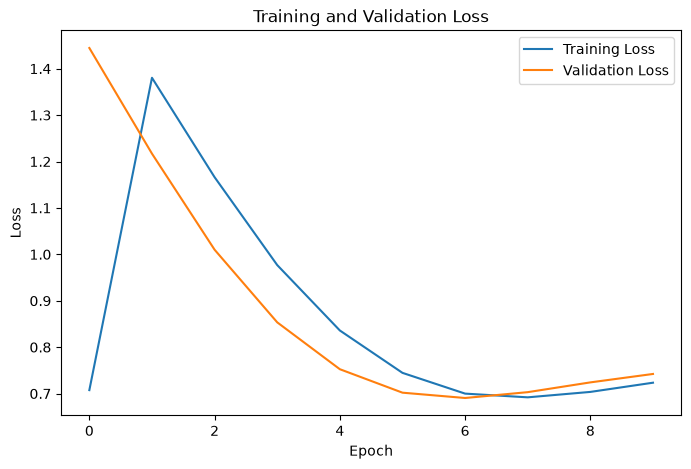

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.show()


## Training and Validation Performance

Both training and validation loss decreased during training.

The validation loss followed the training loss closely.

This indicates that the transformer learned the sequence task without obvious instability.

The loss curves suggest successful learning and acceptable generalization.

In [10]:
def accuracy(
    model,
    X,
    y
):

    model.eval()

    with torch.inference_mode():

        predictions = (
            model(X)
            .argmax(dim=1)
        )

    return (
        predictions == y
    ).float().mean().item()

validation_accuracy = accuracy(
    model,
    X_val,
    y_val
)

print(
    "Validation Accuracy:",
    round(
        validation_accuracy,
        4
    )
)

Validation Accuracy: 0.4967


In [11]:
full_model = model

no_position_model = TinyTransformer()

no_position_model.use_positions = False

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    no_position_model.parameters(),
    lr=0.01
)

for epoch in range(10):

    no_position_model.train()

    optimizer.zero_grad()

    logits = no_position_model(X_train)

    loss = criterion(
        logits,
        y_train
    )

    loss.backward()

    optimizer.step()

no_position_model.eval()

with torch.inference_mode():

    predictions = (
        no_position_model(X_val)
        .argmax(dim=1)
    )

no_position_accuracy = (
    (predictions == y_val)
    .float()
    .mean()
    .item()
)

print(
    "Validation baseline:",
    round(baseline, 3)
)

print(
    "Without positions:",
    round(
        no_position_accuracy,
        4
    )
)

print(
    "With positions:",
    round(
        validation_accuracy,
        4
    )
)

Validation baseline: 0.507
Without positions: 0.5033
With positions: 0.4967


In [12]:
full_model.eval()

with torch.inference_mode():

    predictions = (
        full_model(X_test)
        .argmax(dim=1)
    )

test_accuracy = (
    (predictions == y_test)
    .float()
    .mean()
    .item()
)

print(
    "Final test accuracy:",
    round(
        test_accuracy,
        4
    )
)

Final test accuracy: 0.4733


full_model.eval()

with torch.inference_mode():

    predictions = (
        full_model(
            X_val[:6]
        )
        .argmax(dim=1)
    )

for i in range(6):

    print(
        X_val[i].tolist(),
        "actual",
        y_val[i].item(),
        "predicted",
        predictions[i].item()
    )